# Tutorial: Coordinate Geometries in Soft Potato

The `softpotato.geometry` subpackage is the spatial coordinate engine of the Soft Potato simulator. While the `softpotato.solver` module integrates the temporal reaction-diffusion partial differential equations, the `geometry` module encapsulates the underlying coordinate system metrics, finite-difference differential operators (Laplacian $\nabla^2$ and gradient $\nabla$), normal interfacial flux evaluation ($J = -D \partial c / \partial n$), and active electrode surface integration for Faradaic currents ($I = n F A J$).

---

## 1. Introduction: The Laplacian Operator Across Coordinate Geometries

In electrochemical and mass-transport systems under diffusion control, species concentration profiles evolve according to Fick's second law:

$$\frac{\partial c}{\partial t} = D \nabla^2 c$$

Where $\nabla^2$ is the spatial **Laplacian operator**. The mathematical and physical behavior of diffusion is dictated by the symmetry of the coordinate geometry.

### Mathematical Formulation of the Curvilinear Laplacian

For one-dimensional isotropic mass transport in coordinate systems with geometric symmetry, the Laplacian operator takes the unified form:

$$\nabla^2 c = \frac{1}{r^p} \frac{\partial}{\partial r}\left( r^p \frac{\partial c}{\partial r} \right) = \frac{\partial^2 c}{\partial r^2} + \frac{p}{r} \frac{\partial c}{\partial r}$$

where $p \in \{0, 1, 2\}$ is the **geometric symmetry factor**:

- **Planar Cartesian coordinates** ($p = 0$, $r \to x$):
  $$\nabla^2 c = \frac{\partial^2 c}{\partial x^2}$$

- **Cylindrical radial coordinates** ($p = 1$, $r \ge r_0$):
  $$\nabla^2 c = \frac{\partial^2 c}{\partial r^2} + \frac{1}{r} \frac{\partial c}{\partial r}$$

- **Spherical radial coordinates** ($p = 2$, $r \ge r_0$):
  $$\nabla^2 c = \frac{\partial^2 c}{\partial r^2} + \frac{2}{r} \frac{\partial c}{\partial r}$$

### Physical Origin of the Curvature Term $\frac{p}{r}\frac{\partial c}{\partial r}$

To understand the profound differences between these three operators, consider how the diffusion area expands with distance $r$ from the electrode interface:

1. **Planar Macroelectrode ($p = 0$):**
   - The electrode is an infinite flat plane located at $x = 0$.
   - The cross-sectional diffusion area $A(x) = A$ is strictly **constant** for all distances $x \ge 0$.
   - Particles diffuse along parallel, non-converging trajectories. Because the area does not change with distance ($dA/dx = 0$), the first derivative term vanishes ($p = 0$).
   - Consequently, the depletion zone expands continuously into the bulk solution ($\delta \approx 6\sqrt{Dt}$). The interfacial concentration gradient continuously flattens as $t^{-1/2}$, and the Faradaic current decays toward zero ($I \to 0$ as $t \to \infty$).

2. **Cylindrical Wire/Fiber Microelectrode ($p = 1$):**
   - The electrode is a cylindrical wire or carbon fiber of radius $r_0$ and active length $L$ ($L \gg r_0$, neglecting end effects).
   - The surface area of concentric cylindrical shells increases **linearly** with radius:
     $$A(r) = 2 \pi r L$$
   - The curvature term $\frac{1}{r}\frac{\partial c}{\partial r}$ accounts for this radial divergence: as molecules diffuse away from the wire, they enter cylindrical shells of expanding volume ($dV = 2\pi r L dr$).
   - Conversely, when the electrode consumes reactant, molecules converge from a 2D radial field into the small wire radius $r_0$.
   - This 2D radial convergence substantially enhances interfacial flux compared to planar diffusion. While cylindrical diffusion in an infinite domain does not reach a true non-zero steady state, it decays very slowly (logarithmically), exhibiting a prolonged "quasi-steady state".

3. **Spherical Microelectrode or Droplet ($p = 2$):**
   - The electrode is a sphere of radius $r_0$ (e.g., hanging mercury drop or microhemisphere on an insulating substrate).
   - The surface area of concentric spherical shells increases **quadratically** with radius:
     $$A(r) = 4 \pi r^2$$
   - The curvature term $\frac{2}{r}\frac{\partial c}{\partial r}$ represents strong 3D geometric divergence ($dV = 4\pi r^2 dr$).
   - Reactant molecules converge from all three dimensions into the microscopic spherical sink. This 3D convergent flux is so powerful that it completely balances diffusive depletion, establishing a time-independent **steady-state concentration profile**:
     $$c_{\text{ss}}(r) = c^* \left(1 - \frac{r_0}{r}\right)$$
     and sustaining a constant, non-zero **steady-state limiting current**:
     $$I_{\text{ss}} = 4 \pi n F D c^* r_0$$

### Summary of Geometric Properties in Soft Potato

| Geometry Class | Built-in Alias | Symmetry $p$ | Spatial Coordinate | Laplacian Operator $\nabla^2 c$ | Active Surface Area $A$ | Steady-State Current ($t \to \infty$) |
| :--- | :--- | :---: | :---: | :--- | :--- | :--- |
| `PlanarGeometry` | `'planar'`, `'cartesian'`, `'1d'` | $0$ | $x \in [0, L]$ | $\dfrac{\partial^2 c}{\partial x^2}$ | $A_{\text{planar}}$ (user-defined) | $0$ (decays as $t^{-1/2}$) |
| `CylindricalGeometry` | `'cylindrical'`, `'cylinder'`, `'wire'` | $1$ | $r \in [r_0, r_{\max}]$ | $\dfrac{\partial^2 c}{\partial r^2} + \dfrac{1}{r}\dfrac{\partial c}{\partial r}$ | $2 \pi r_0 L$ | Quasi-steady (logarithmic decay) |
| `SphericalGeometry` | `'spherical'`, `'sphere'`, `'hemisphere'` | $2$ | $r \in [r_0, r_{\max}]$ | $\dfrac{\partial^2 c}{\partial r^2} + \dfrac{2}{r}\dfrac{\partial c}{\partial r}$ | $4 \pi r_0^2$ (or $2 \pi r_0^2$) | $4 \pi n F D c^* r_0$ (constant) |

> **Tutorial Focus:**
> In this tutorial, we focus directly on the **`geometries` module** of Soft Potato. We will:
> 1. Test and verify the Laplacian operator across all three geometries on analytical harmonic functions.
> 2. Use minimal code for `DiffusionProblem` and the solver to run potential-step chronoamperometry across **planar**, **spherical**, and **cylindrical** electrodes.
> 3. Plot and compare the concentration profiles in **1D** at a specific time snapshot.
> 4. Map and render the concentration distributions in **2D Cartesian coordinates** ($(x, y)$ cross-sections).
> 5. Plot and contrast the resulting **Faradaic currents** and **current densities** ($j(t)$ vs. $t$ and Cottrell plots $j$ vs. $t^{-1/2}$).

In [1]:
import numpy as np
from softpotato.geometry import PlanarGeometry, SphericalGeometry, CylindricalGeometry

# 1. Planar: c(x) = x²  -->  d²(x²)/dx² = 2.0 everywhere
geom_p = PlanarGeometry(area=1.0)
x_grid = np.linspace(0.0, 1.0, 101)
c_planar = x_grid ** 2
lap_p = geom_p.laplacian(c_planar, x_grid)

# 2. Cylindrical harmonic: c(r) = ln(r)  -->  ∇²(ln r) = d²(ln r)/dr² + (1/r) d(ln r)/dr = -1/r² + 1/r² = 0.0
geom_c = CylindricalGeometry(r0=1.0, length=1.0)
r_grid_c = np.linspace(1.0, 5.0, 201)
c_cyl = np.log(r_grid_c)
lap_c = geom_c.laplacian(c_cyl, r_grid_c)

# 3. Spherical harmonic: c(r) = 1/r  -->  ∇²(1/r) = d²(1/r)/dr² + (2/r) d(1/r)/dr = 2/r³ - 2/r³ = 0.0
geom_s = SphericalGeometry(r0=1.0)
r_grid_s = np.linspace(1.0, 5.0, 201)
c_sphere = 1.0 / r_grid_s
lap_s = geom_s.laplacian(c_sphere, r_grid_s)

print("=== Direct Verification of Laplacian Operators in Soft Potato ===")
print(f"Planar ∇²(x²) mean interior value:        {np.mean(lap_p[1:-1]):.6f} (expected: 2.000000)")
print(f"Cylindrical ∇²(ln r) max interior error:  {np.max(np.abs(lap_c[1:-1])):.2e} (expected: 0.00)")
print(f"Spherical ∇²(1/r) max interior error:     {np.max(np.abs(lap_s[1:-1])):.2e} (expected: 0.00)")

=== Direct Verification of Laplacian Operators in Soft Potato ===
Planar ∇²(x²) mean interior value:        2.000000 (expected: 2.000000)
Cylindrical ∇²(ln r) max interior error:  6.16e-05 (expected: 0.00)
Spherical ∇²(1/r) max interior error:     5.91e-13 (expected: 0.00)


---

## 2. Minimal Code to Run Multi-Geometry Simulations

Below is the complete, self-contained minimal code required to set up the physical parameters, instantiate the three coordinate geometries, formulate their corresponding `DiffusionProblem` specifications, and execute the numerical solver.

We model a standard **Cottrell potential-step experiment**: an electrode initially surrounded by bulk solution with concentration $c^* = 1.0\text{ mol/m}^3$ ($1\text{ mM}$) is stepped to a potential where reactant consumption is instantaneous ($c(r_0, t) = 0$).

### Experimental Parameters:
- Diffusivity: $D = 1.0 \times 10^{-9}\text{ m}^2/\text{s} = 1.0 \times 10^{-5}\text{ cm}^2/\text{s}$ (canonical aqueous ion)
- Bulk concentration: $c^* = 1.0\text{ mol/m}^3$ ($1.0\text{ mM}$)
- Microelectrode radius: $r_0 = 25\ \mu\text{m} = 2.5 \times 10^{-5}\text{ m}$ (for sphere and cylinder)
- Cylindrical wire length: $L = 1.0\text{ cm} = 1.0 \times 10^{-2}\text{ m}$
- Planar macroelectrode area: $A = 1.0\text{ cm}^2 = 1.0 \times 10^{-4}\text{ m}^2$
- Experiment duration: $t_{\text{max}} = 1.0\text{ s}$
- Semi-infinite diffusion layer thickness: $\delta \approx 6\sqrt{Dt_{\text{max}}} \approx 190\ \mu\text{m}$

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
import matplotlib.pyplot as plt
from softpotato.geometry import PlanarGeometry, SphericalGeometry, CylindricalGeometry
from softpotato.solver import DiffusionProblem, DirichletBC, get_solver

# 1. Physical parameters
D = 1e-9          # Diffusivity (m²/s)
c_bulk = 1.0      # Bulk concentration (mol/m³)
r0 = 25e-6        # Microelectrode radius (m, 25 µm)
L_wire = 1e-2     # Cylindrical wire length (m, 1 cm)
A_planar = 1e-4   # Planar macroelectrode area (m², 1 cm²)
t_max = 1.0       # Experiment duration (s)
delta = 6.0 * np.sqrt(D * t_max)  # Diffusion penetration layer (~190 µm)

# 2. Geometry instances
geom_planar = PlanarGeometry(area=A_planar)
geom_sphere = SphericalGeometry(r0=r0)
geom_cyl = CylindricalGeometry(r0=r0, length=L_wire)

# 3. Spatial grids (planar starts at 0; curvilinear starts at r0 > 0)
n_pts = 150
grid_planar = np.linspace(0.0, delta, n_pts)
grid_radial = np.linspace(r0, r0 + delta, n_pts)

# 4. Minimal DiffusionProblem setups (Cottrell potential step)
prob_planar = DiffusionProblem(
    grid=grid_planar,
    diffusivity={"c": D},
    boundary_conditions={"c": (DirichletBC(0.0), DirichletBC(c_bulk))},
    initial_conditions={"c": c_bulk},
    geometry=geom_planar,
)

prob_sphere = DiffusionProblem(
    grid=grid_radial,
    diffusivity={"c": D},
    boundary_conditions={"c": (DirichletBC(0.0), DirichletBC(c_bulk))},
    initial_conditions={"c": c_bulk},
    geometry=geom_sphere,
)

prob_cyl = DiffusionProblem(
    grid=grid_radial,
    diffusivity={"c": D},
    boundary_conditions={"c": (DirichletBC(0.0), DirichletBC(c_bulk))},
    initial_conditions={"c": c_bulk},
    geometry=geom_cyl,
)

# 5. Solver execution with SciPy Method of Lines (Radau)
solver = get_solver("scipy_ivp")
t_eval = np.linspace(0.01, t_max, 100)

res_planar = solver.solve(prob_planar, t_span=(0.0, t_max), t_eval=t_eval)
res_sphere = solver.solve(prob_sphere, t_span=(0.0, t_max), t_eval=t_eval)
res_cyl = solver.solve(prob_cyl, t_span=(0.0, t_max), t_eval=t_eval)

print("=== Multi-Geometry Simulation Execution Summary ===")
print(f"Planar:      {res_planar.message} (area = {geom_planar.area:.2e} m²)")
print(f"Spherical:   {res_sphere.message} (area = {geom_sphere.area:.2e} m²)")
print(f"Cylindrical: {res_cyl.message} (area = {geom_cyl.area:.2e} m²)")

=== Multi-Geometry Simulation Execution Summary ===
Planar:      SciPy solve_ivp completed successfully. (area = 1.00e-04 m²)
Spherical:   SciPy solve_ivp completed successfully. (area = 7.85e-09 m²)
Cylindrical: SciPy solve_ivp completed successfully. (area = 1.57e-06 m²)


---

## 3. Planar Geometry (`PlanarGeometry`, $p = 0$)

The `PlanarGeometry` class models one-dimensional linear diffusion perpendicular to a flat macroelectrode surface:

$$\nabla^2 c = \frac{\partial^2 c}{\partial x^2}$$

### Key Characteristics:
- **Spatial coordinate:** $x \in [0, x_{\max}]$ where $x = 0$ is the electrode boundary and $x_{\max} = \delta$.
- **Active surface area:** $A = A_{\text{planar}}$ (user-defined, constant for all $x$).
- **Normal interfacial flux:**
  $$J_{\text{left}} = -D \left.\frac{\partial c}{\partial x}\right|_{x=0}$$
- **Faradaic current:**
  $$I(t) = n F A J_{\text{left}}(t)$$
- **Analytical Cottrell current:**
  $$I_{\text{Cottrell}}(t) = \frac{n F A D^{1/2} c^*}{\pi^{1/2} t^{1/2}}$$

Because there is no curvature divergence ($p = 0$), the concentration gradient at the electrode diminishes continually as $t^{-1/2}$, approaching zero as $t \to \infty$.

In [3]:
from softpotato.constants import FARADAY

# Inspect PlanarGeometry properties
print("=== Planar Geometry Properties ===")
print(f"Identifier:      {geom_planar.name}")
print(f"Symmetry factor: p = {geom_planar.p}")
print(f"Coordinate name: '{geom_planar.coordinate_name}'")
print(f"Electrode area:  {geom_planar.area:.4e} m² ({geom_planar.area * 1e4:.2f} cm²)")

# Compare numerical current with analytical Cottrell at t = 1.0 s
t_idx_1s = np.argmin(np.abs(t_eval - 1.0))
I_num_planar_1s = res_planar.currents["c"][t_idx_1s]
I_ana_planar_1s = -FARADAY * A_planar * np.sqrt(D) * c_bulk / (np.sqrt(np.pi * 1.0))

print(f"Numerical current at t = 1.0 s:  {I_num_planar_1s:.6e} A")
print(f"Analytical Cottrell at t = 1.0 s: {I_ana_planar_1s:.6e} A")
print(f"Relative error:                  {abs((I_num_planar_1s - I_ana_planar_1s) / I_ana_planar_1s) * 100:.3f}%")

=== Planar Geometry Properties ===
Identifier:      planar
Symmetry factor: p = 0
Coordinate name: 'x'
Electrode area:  1.0000e-04 m² (1.00 cm²)
Numerical current at t = 1.0 s:  -1.721941e-04 A
Analytical Cottrell at t = 1.0 s: -1.721418e-04 A
Relative error:                  0.030%


---

## 4. Spherical Geometry (`SphericalGeometry`, $p = 2$)

The `SphericalGeometry` class models spherically symmetric radial mass transport to or from a spherical microelectrode or hanging mercury drop of radius $r_0$:

$$\nabla^2 c = \frac{\partial^2 c}{\partial r^2} + \frac{2}{r} \frac{\partial c}{\partial r}$$

### Key Characteristics:
- **Spatial coordinate:** $r \in [r_0, r_{\max}]$ where $r_0$ is the electrode radius.
- **Domain constraint:** The coordinate grid **must satisfy $r_0 = \text{grid}[0] > 0$**. Radial diffusion cannot start at $r=0$ because the $2/r$ divergence term is singular at the origin.
- **Active surface area:** $A = 4 \pi r_0^2$ (or $A = 2 \pi r_0^2$ for a hemisphere on an insulating plane via `hemisphere=True`).
- **Analytical concentration profile:**
  $$c_{\text{spherical}}(r, t) = c^* \left[ 1 - \frac{r_0}{r} \text{erfc}\left( \frac{r - r_0}{2 \sqrt{D t}} \right) \right]$$
- **Analytical Faradaic current:**
  $$I_{\text{spherical}}(t) = 4 \pi n F D c^* r_0 \left( 1 + \frac{r_0}{\sqrt{\pi D t}} \right) = I_{\text{ss}} \left( 1 + \frac{r_0}{\sqrt{\pi D t}} \right)$$
- **Steady-state limiting current ($t \to \infty$):**
  $$I_{\text{ss}} = 4 \pi n F D c^* r_0$$

At short times ($t \ll r_0^2 / \pi D$), the transient term dominates and the electrode behaves like a planar surface. At long times ($t \gg r_0^2 / \pi D$), the transient decays and the current asymptotes to the non-zero steady-state value $I_{\text{ss}}$!

In [4]:
# Inspect SphericalGeometry properties
print("=== Spherical Geometry Properties ===")
print(f"Identifier:      {geom_sphere.name}")
print(f"Symmetry factor: p = {geom_sphere.p}")
print(f"Coordinate name: '{geom_sphere.coordinate_name}'")
print(f"Electrode radius: r0 = {geom_sphere.r0 * 1e6:.1f} µm ({geom_sphere.r0:.3e} m)")
print(f"Electrode area:  4π r0² = {geom_sphere.area:.4e} m² ({geom_sphere.area * 1e4:.4e} cm²)")

# Analytical steady-state limiting current
I_ss_theoretical = -4.0 * np.pi * FARADAY * D * c_bulk * r0
I_num_sphere_1s = res_sphere.currents["c"][t_idx_1s]
I_ana_sphere_1s = -4.0 * np.pi * FARADAY * D * c_bulk * r0 * (1.0 + r0 / np.sqrt(np.pi * D * 1.0))

print(f"Steady-state limiting current (I_ss): {I_ss_theoretical:.6e} A")
print(f"Numerical current at t = 1.0 s:       {I_num_sphere_1s:.6e} A")
print(f"Analytical current at t = 1.0 s:      {I_ana_sphere_1s:.6e} A")
print(f"Relative error vs analytical:         {abs((I_num_sphere_1s - I_ana_sphere_1s) / I_ana_sphere_1s) * 100:.3f}%")

=== Spherical Geometry Properties ===
Identifier:      spherical
Symmetry factor: p = 2
Coordinate name: 'r'
Electrode radius: r0 = 25.0 µm (2.500e-05 m)
Electrode area:  4π r0² = 7.8540e-09 m² (7.8540e-05 cm²)
Steady-state limiting current (I_ss): -3.031176e-08 A
Numerical current at t = 1.0 s:       -4.363895e-08 A
Analytical current at t = 1.0 s:      -4.383175e-08 A
Relative error vs analytical:         0.440%


---

## 5. Cylindrical Geometry (`CylindricalGeometry`, $p = 1$)

The `CylindricalGeometry` class models axisymmetric radial diffusion to or from a cylindrical wire or carbon fiber microelectrode of radius $r_0$ and active length $L$:

$$\nabla^2 c = \frac{\partial^2 c}{\partial r^2} + \frac{1}{r} \frac{\partial c}{\partial r}$$

### Key Characteristics:
- **Spatial coordinate:** $r \in [r_0, r_{\max}]$ with $r_0 > 0$.
- **Active lateral surface area:** $A = 2 \pi r_0 L$ (neglecting end effects when $L \gg r_0$).
- **Curvature effect ($p = 1$):** Because the area of concentric cylindrical shells increases linearly with $r$, radial divergence provides intermediate mass-transport enhancement between planar ($p = 0$) and spherical ($p = 2$).
- **Quasi-steady state:** Unlike spherical microelectrodes, 2D cylindrical diffusion in an infinite medium does not admit a non-zero time-independent steady state. Instead, the current decays logarithmically at long times:
  $$I(t) \propto \frac{2 \pi n F D c^* L}{\ln(4 D t / r_0^2)}$$
  This slow decay provides sustained currents that are orders of magnitude higher than planar macroelectrodes on a per-area basis.

In [5]:
# Inspect CylindricalGeometry properties
print("=== Cylindrical Geometry Properties ===")
print(f"Identifier:      {geom_cyl.name}")
print(f"Symmetry factor: p = {geom_cyl.p}")
print(f"Coordinate name: '{geom_cyl.coordinate_name}'")
print(f"Electrode radius: r0 = {geom_cyl.r0 * 1e6:.1f} µm ({geom_cyl.r0:.3e} m)")
print(f"Electrode length: L  = {geom_cyl.length * 1e2:.1f} cm ({geom_cyl.length:.3e} m)")
print(f"Lateral area:    2π r0 L = {geom_cyl.area:.4e} m² ({geom_cyl.area * 1e4:.4e} cm²)")

I_num_cyl_1s = res_cyl.currents["c"][t_idx_1s]
print(f"Numerical current at t = 1.0 s: {I_num_cyl_1s:.6e} A")

=== Cylindrical Geometry Properties ===
Identifier:      cylindrical
Symmetry factor: p = 1
Coordinate name: 'r'
Electrode radius: r0 = 25.0 µm (2.500e-05 m)
Electrode length: L  = 1.0 cm (1.000e-02 m)
Lateral area:    2π r0 L = 1.5708e-06 m² (1.5708e-02 cm²)
Numerical current at t = 1.0 s: -5.167009e-06 A


---

## 6. Plotting Concentration Profiles in 1D at a Specific Time

To understand how geometry controls diffusion, we examine the concentration profiles at a specific snapshot in time:

$$t^* = 0.5\text{ s}$$

We inspect two complementary 1D representations:
1. **Coordinate-relative profiles:** $c(x)$ vs. $x$ for planar, and $c(r)$ vs. $r$ for spherical and cylindrical, marking the electrode boundary $r = r_0$.
2. **Direct geometric comparison:** Normalized concentration $c / c^*$ plotted against the **distance from the electrode surface**:
   $$\Delta r = r - r_0 \quad (\text{or } \Delta x = x \text{ for planar})$$
   with the theoretical spherical steady-state asymptote $c_{\text{ss}}(r) = c^*(1 - r_0 / r)$ overlaid.

### Physical Insight:
- **Spherical ($p = 2$)** exhibits the **steepest concentration gradient** at the electrode surface because 3D convergent flux funnels material from an expanding volume ($V \propto r^3$).
- **Cylindrical ($p = 1$)** exhibits intermediate gradient steepness ($V \propto r^2$).
- **Planar ($p = 0$)** has the **shallowest gradient** ($V \propto x$) because there is no geometric convergence.

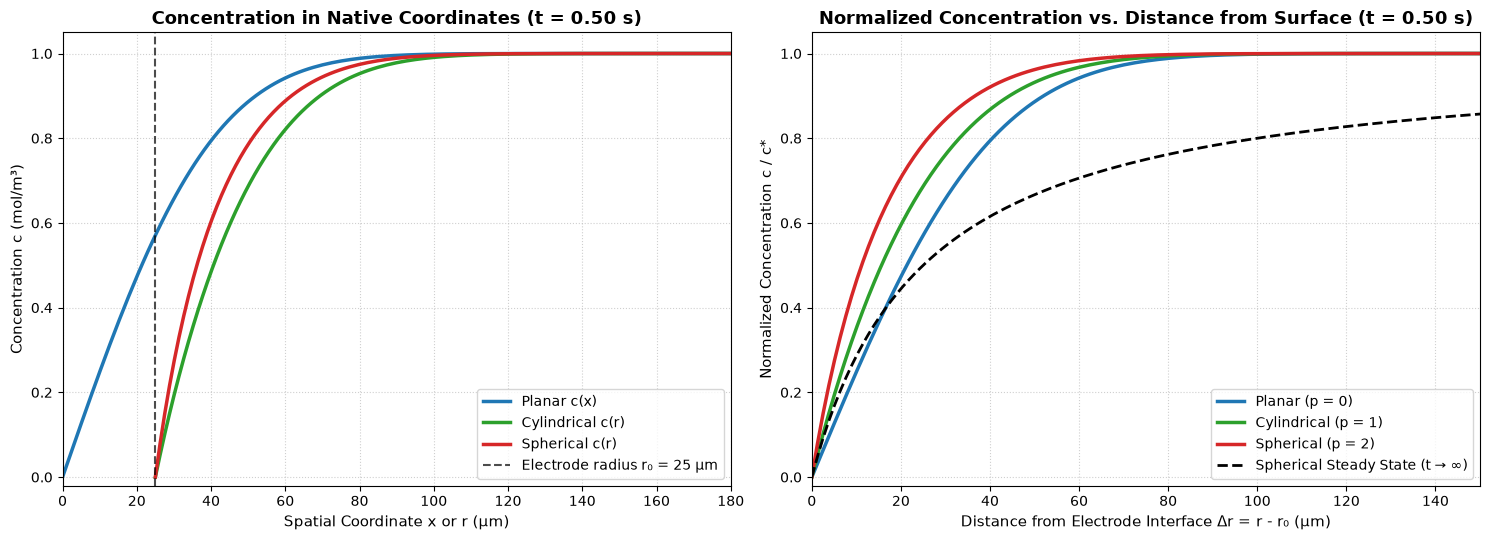

In [6]:
# Select snapshot time t* = 0.5 s
t_snapshot = 0.5
t_idx = np.argmin(np.abs(t_eval - t_snapshot))
t_actual = t_eval[t_idx]

c_p = res_planar["c"][t_idx]
c_s = res_sphere["c"][t_idx]
c_c = res_cyl["c"][t_idx]

# Distance from electrode interface (in µm)
dist_p = grid_planar * 1e6
dist_r = (grid_radial - r0) * 1e6

# Spherical analytical steady-state profile
c_ss_sphere = c_bulk * (1.0 - r0 / grid_radial)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Native Spatial Coordinates
ax1 = axes[0]
ax1.plot(grid_planar * 1e6, c_p, label="Planar c(x)", color="#1f77b4", lw=2.5)
ax1.plot(grid_radial * 1e6, c_c, label="Cylindrical c(r)", color="#2ca02c", lw=2.5)
ax1.plot(grid_radial * 1e6, c_s, label="Spherical c(r)", color="#d62728", lw=2.5)
ax1.axvline(r0 * 1e6, color="black", linestyle="--", alpha=0.7, label=f"Electrode radius r₀ = {r0 * 1e6:.0f} µm")
ax1.set_title(f"Concentration in Native Coordinates (t = {t_actual:.2f} s)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Spatial Coordinate x or r (µm)", fontsize=11)
ax1.set_ylabel("Concentration c (mol/m³)", fontsize=11)
ax1.set_xlim(0, 180)
ax1.set_ylim(-0.02, 1.05)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)

# Subplot 2: Distance from Electrode Interface
ax2 = axes[1]
ax2.plot(dist_p, c_p / c_bulk, label="Planar (p = 0)", color="#1f77b4", lw=2.5)
ax2.plot(dist_r, c_c / c_bulk, label="Cylindrical (p = 1)", color="#2ca02c", lw=2.5)
ax2.plot(dist_r, c_s / c_bulk, label="Spherical (p = 2)", color="#d62728", lw=2.5)
ax2.plot(dist_r, c_ss_sphere / c_bulk, "k--", lw=2.0, label="Spherical Steady State (t → ∞)")
ax2.set_title(f"Normalized Concentration vs. Distance from Surface (t = {t_actual:.2f} s)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Distance from Electrode Interface Δr = r - r₀ (µm)", fontsize=11)
ax2.set_ylabel("Normalized Concentration c / c*", fontsize=11)
ax2.set_xlim(0, 150)
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

---

## 7. Plotting Concentration Profiles in 2D Cartesian Coordinates

While numerical solvers integrate in 1D along the symmetry axis ($x$ or $r$), real electrodes occupy two- and three-dimensional physical space:
- **Planar Macroelectrode:** Viewed in cross-section perpendicular to the electrode surface, the electrode is a flat vertical wall at $x = 0$. Diffusion takes place in the half-space $x > 0$. The concentration depends only on $x$ and is strictly invariant along $y$, forming **straight vertical isoconcentration contours**.
- **Spherical Microelectrode:** Viewed across any equatorial plane passing through the origin, the spherical electrode forms a circular solid boundary of radius $r_0$ centered at the origin: $r = \sqrt{x^2 + y^2} < r_0$. In the electrolyte ($r \ge r_0$), concentration depends only on radius $r$, producing **concentric circular isoconcentration contours**.
- **Cylindrical Wire Microelectrode:** Viewed in transverse cross-section perpendicular to the longitudinal cylinder axis, the wire forms a circular cross-section of radius $r_0$ centered at the origin: $r = \sqrt{x^2 + y^2} < r_0$. Concentric circular contours surround the wire in the transverse $(x, y)$ plane.

Below, we reconstruct the 2D Cartesian concentration fields at $t^* = 0.5\text{ s}$ by interpolating the 1D profiles onto 2D Cartesian coordinate meshes.

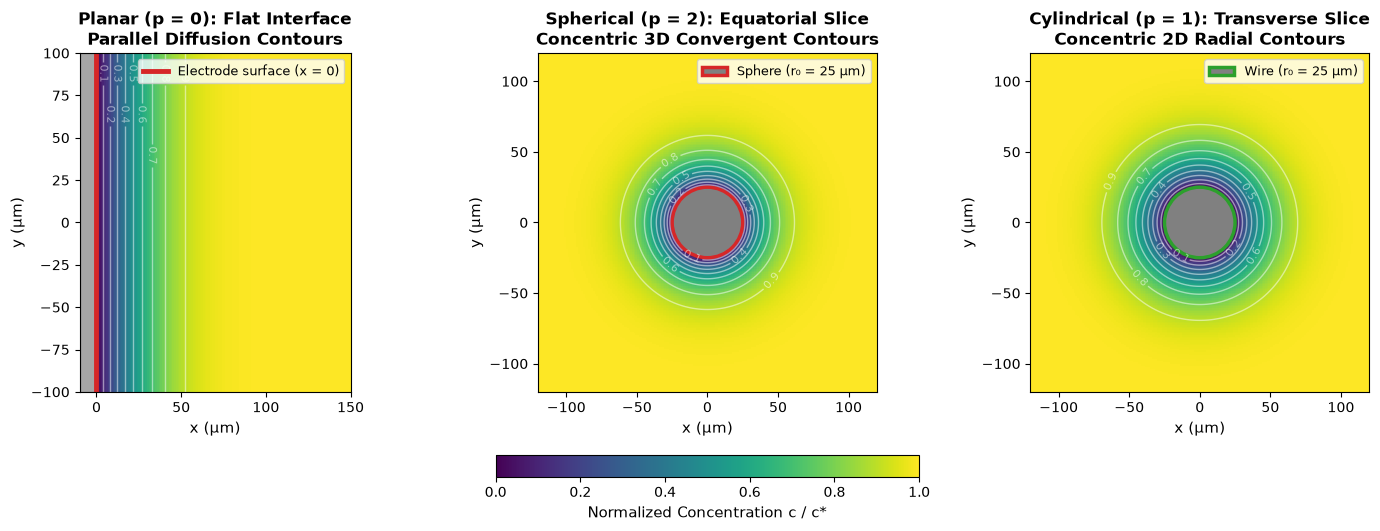

In [7]:
from scipy.interpolate import interp1d

# Interpolation functions for 1D profiles at t = 0.5 s
interp_planar = interp1d(grid_planar, c_p, bounds_error=False, fill_value=c_bulk)
interp_sphere = interp1d(grid_radial, c_s, bounds_error=False, fill_value=c_bulk)
interp_cyl = interp1d(grid_radial, c_c, bounds_error=False, fill_value=c_bulk)

# 1. 2D Planar Mesh: x in [0, 150 µm], y in [-100, 100 µm]
x_p = np.linspace(0.0, 150e-6, 150)
y_p = np.linspace(-100e-6, 100e-6, 150)
X_p, Y_p = np.meshgrid(x_p, y_p)
C_2d_planar = interp_planar(X_p) / c_bulk

# 2. 2D Circular Mesh for Sphere and Cylinder: x, y in [-120 µm, 120 µm]
box_limit = 120e-6
xy_grid = np.linspace(-box_limit, box_limit, 201)
X_circ, Y_circ = np.meshgrid(xy_grid, xy_grid)
R_circ = np.sqrt(X_circ**2 + Y_circ**2)

# Mask region inside electrode (r < r0) as NaN
C_2d_sphere = np.full_like(R_circ, np.nan)
mask_s = R_circ >= r0
C_2d_sphere[mask_s] = interp_sphere(R_circ[mask_s]) / c_bulk

C_2d_cyl = np.full_like(R_circ, np.nan)
mask_c = R_circ >= r0
C_2d_cyl[mask_c] = interp_cyl(R_circ[mask_c]) / c_bulk

# Plot 3-panel 2D Cartesian Concentration Fields
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
contour_levels = np.linspace(0.1, 0.9, 9)

# Panel 1: Planar 2D Cross-Section
ax1 = axes[0]
im1 = ax1.pcolormesh(X_p * 1e6, Y_p * 1e6, C_2d_planar, cmap="viridis", vmin=0.0, vmax=1.0, shading="auto")
cs1 = ax1.contour(X_p * 1e6, Y_p * 1e6, C_2d_planar, levels=contour_levels, colors="white", alpha=0.5, linewidths=1.0)
ax1.clabel(cs1, fmt="%.1f", fontsize=8)
ax1.axvline(0.0, color="#d62728", lw=3.5, label="Electrode surface (x = 0)")
ax1.fill_betweenx(y_p * 1e6, -10, 0, color="gray", alpha=0.7)
ax1.set_title("Planar (p = 0): Flat Interface\nParallel Diffusion Contours", fontsize=12, fontweight="bold")
ax1.set_xlabel("x (µm)", fontsize=11)
ax1.set_ylabel("y (µm)", fontsize=11)
ax1.set_xlim(-10, 150)
ax1.set_ylim(-100, 100)
ax1.set_aspect("equal")
ax1.legend(loc="upper right", fontsize=9)

# Panel 2: Spherical 2D Equatorial Slice
ax2 = axes[1]
im2 = ax2.pcolormesh(X_circ * 1e6, Y_circ * 1e6, C_2d_sphere, cmap="viridis", vmin=0.0, vmax=1.0, shading="auto")
cs2 = ax2.contour(X_circ * 1e6, Y_circ * 1e6, C_2d_sphere, levels=contour_levels, colors="white", alpha=0.5, linewidths=1.0)
ax2.clabel(cs2, fmt="%.1f", fontsize=8)
circle_s = plt.Circle((0, 0), r0 * 1e6, color="gray", ec="#d62728", lw=2.5, label=f"Sphere (r₀ = {r0 * 1e6:.0f} µm)")
ax2.add_patch(circle_s)
ax2.set_title("Spherical (p = 2): Equatorial Slice\nConcentric 3D Convergent Contours", fontsize=12, fontweight="bold")
ax2.set_xlabel("x (µm)", fontsize=11)
ax2.set_ylabel("y (µm)", fontsize=11)
ax2.set_xlim(-box_limit * 1e6, box_limit * 1e6)
ax2.set_ylim(-box_limit * 1e6, box_limit * 1e6)
ax2.set_aspect("equal")
ax2.legend(loc="upper right", fontsize=9)

# Panel 3: Cylindrical 2D Transverse Cross-Section
ax3 = axes[2]
im3 = ax3.pcolormesh(X_circ * 1e6, Y_circ * 1e6, C_2d_cyl, cmap="viridis", vmin=0.0, vmax=1.0, shading="auto")
cs3 = ax3.contour(X_circ * 1e6, Y_circ * 1e6, C_2d_cyl, levels=contour_levels, colors="white", alpha=0.5, linewidths=1.0)
ax3.clabel(cs3, fmt="%.1f", fontsize=8)
circle_c = plt.Circle((0, 0), r0 * 1e6, color="gray", ec="#2ca02c", lw=2.5, label=f"Wire (r₀ = {r0 * 1e6:.0f} µm)")
ax3.add_patch(circle_c)
ax3.set_title("Cylindrical (p = 1): Transverse Slice\nConcentric 2D Radial Contours", fontsize=12, fontweight="bold")
ax3.set_xlabel("x (µm)", fontsize=11)
ax3.set_ylabel("y (µm)", fontsize=11)
ax3.set_xlim(-box_limit * 1e6, box_limit * 1e6)
ax3.set_ylim(-box_limit * 1e6, box_limit * 1e6)
ax3.set_aspect("equal")
ax3.legend(loc="upper right", fontsize=9)

# Shared Colorbar
cbar = fig.colorbar(im3, ax=axes, orientation="horizontal", fraction=0.05, pad=0.15)
cbar.set_label("Normalized Concentration c / c*", fontsize=11)

plt.show()

---

## 8. Plotting the Resulting Faradaic Currents

The electrochemical Faradaic current measured at an electrode is the integral of the normal diffusion flux over the active surface area:

$$I(t) = n F A J_{\text{left}}(t)$$

Because different geometries have vastly different electrode areas ($A_{\text{planar}} = 1\text{ cm}^2$, $A_{\text{sphere}} \approx 7.85 \times 10^{-5}\text{ cm}^2$, $A_{\text{cyl}} \approx 1.57 \times 10^{-2}\text{ cm}^2$), comparing raw currents $I(t)$ reflects primarily the geometric size. To directly compare the **mass-transport efficiency** across geometries, electrochemists normalize current by area to obtain the **current density**:

$$j(t) = \frac{|I(t)|}{A} = n F |J_{\text{left}}(t)|$$

### The Cottrell Diagnostic Plot ($j$ vs. $t^{-1/2}$)
Plotting $j(t)$ against $t^{-1/2}$ reveals the fundamental signature of geometric curvature:
- **Planar ($p = 0$):**
  $$j_{\text{planar}}(t) = \frac{n F D^{1/2} c^*}{\pi^{1/2}} t^{-1/2}$$
  Produces a straight line that passes directly through the origin ($j \to 0$ as $t^{-1/2} \to 0$).
- **Spherical ($p = 2$):**
  $$j_{\text{spherical}}(t) = n F D c^* \left( \frac{1}{\sqrt{\pi D t}} + \frac{1}{r_0} \right) = \frac{n F D^{1/2} c^*}{\pi^{1/2}} t^{-1/2} + \frac{n F D c^*}{r_0}$$
  Has the exact same slope as the planar Cottrell line, but features a **positive non-zero y-intercept** equal to the steady-state limiting current density $j_{\text{ss}} = n F D c^* / r_0$!
- **Cylindrical ($p = 1$):**
  Exhibits enhanced current density intermediate between planar and spherical, decaying very slowly as a logarithmic quasi-steady state.

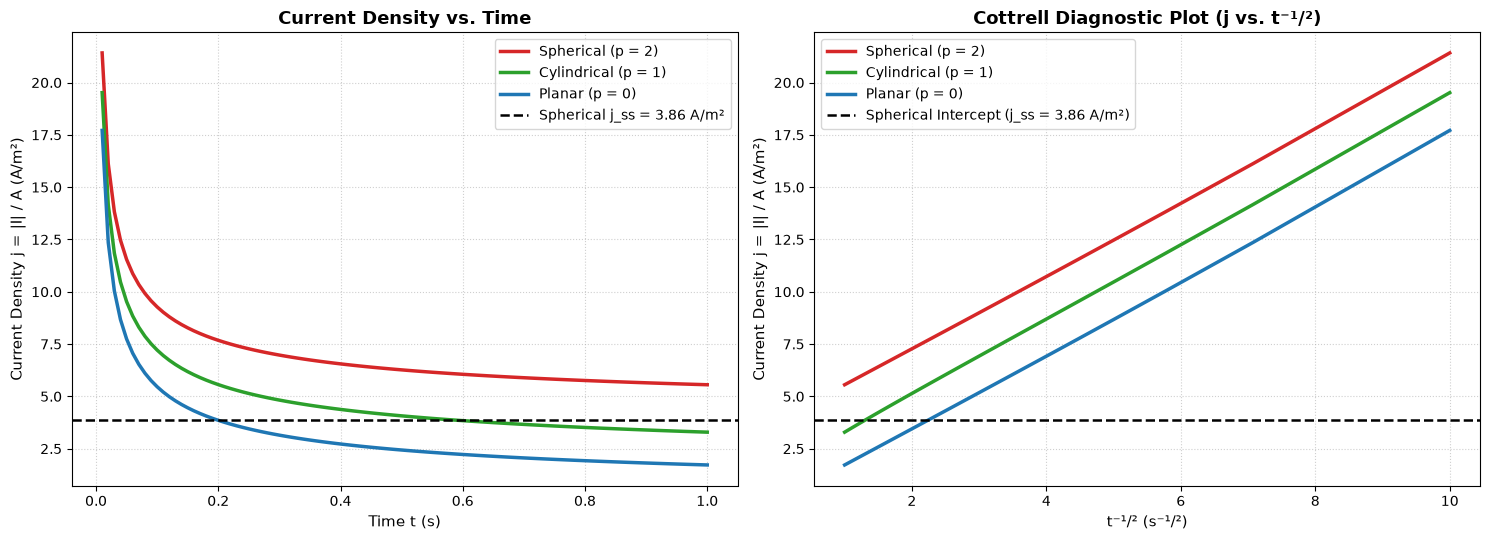

In [8]:
# Extract current densities: j(t) = |I(t)| / A  (A/m²)
j_planar = np.abs(res_planar.currents["c"]) / geom_planar.area
j_sphere = np.abs(res_sphere.currents["c"]) / geom_sphere.area
j_cyl = np.abs(res_cyl.currents["c"]) / geom_cyl.area

# Theoretical steady-state current density for sphere
j_ss_sphere = FARADAY * D * c_bulk / r0  # A/m²

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Current Density vs. Time
ax1 = axes[0]
ax1.plot(t_eval, j_sphere, label="Spherical (p = 2)", color="#d62728", lw=2.5)
ax1.plot(t_eval, j_cyl, label="Cylindrical (p = 1)", color="#2ca02c", lw=2.5)
ax1.plot(t_eval, j_planar, label="Planar (p = 0)", color="#1f77b4", lw=2.5)
ax1.axhline(j_ss_sphere, color="black", linestyle="--", lw=1.8, label=f"Spherical j_ss = {j_ss_sphere:.2f} A/m²")
ax1.set_title("Current Density vs. Time", fontsize=13, fontweight="bold")
ax1.set_xlabel("Time t (s)", fontsize=11)
ax1.set_ylabel("Current Density j = |I| / A (A/m²)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", frameon=True)

# Subplot 2: Cottrell Diagnostic Plot (j vs. t^(-1/2))
t_inv_sqrt = 1.0 / np.sqrt(t_eval)
ax2 = axes[1]
ax2.plot(t_inv_sqrt, j_sphere, label="Spherical (p = 2)", color="#d62728", lw=2.5)
ax2.plot(t_inv_sqrt, j_cyl, label="Cylindrical (p = 1)", color="#2ca02c", lw=2.5)
ax2.plot(t_inv_sqrt, j_planar, label="Planar (p = 0)", color="#1f77b4", lw=2.5)
ax2.axhline(j_ss_sphere, color="black", linestyle="--", lw=1.8, label=f"Spherical Intercept (j_ss = {j_ss_sphere:.2f} A/m²)")
ax2.set_title("Cottrell Diagnostic Plot (j vs. t⁻¹/²)", fontsize=13, fontweight="bold")
ax2.set_xlabel("t⁻¹/² (s⁻¹/²)", fontsize=11)
ax2.set_ylabel("Current Density j = |I| / A (A/m²)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

---

## 9. Summary & Best Practices

In this tutorial, we demonstrated how the `softpotato.geometry` subpackage defines and handles spatial coordinate systems, differential operators, surface fluxes, and Faradaic currents:

### Key Takeaways:
1. **The Laplacian Curvature Term $\frac{p}{r}\frac{\partial c}{\partial r}$:**
   - Arises from the geometric divergence of area and volume elements in curvilinear coordinates.
   - Vanishes for planar macroelectrodes ($p = 0$).
   - Enhances radial mass transport in cylindrical wires ($p = 1$), yielding sustained quasi-steady currents.
   - Funnels 3D convergent flux into spherical microelectrodes ($p = 2$), establishing a true time-independent steady state with limiting current $I_{\text{ss}} = 4 \pi n F D c^* r_0$.

2. **Best Practices When Setting Up Curvilinear Geometries:**
   - **Radial Grid Constraint:** For `SphericalGeometry` and `CylindricalGeometry`, the spatial grid **must strictly start at $r_0 > 0$** (`grid[0] > 0`). Never start a radial mesh at $r = 0$.
   - **Outer Domain Sizing:** Choose the bulk domain boundary sufficiently far into solution: $r_{\max} \ge r_0 + 6\sqrt{Dt_{\text{max}}}$.
   - **Solver Selection:** While `explicit` works with small time steps, `get_solver("scipy_ivp")` (or `'crank_nicolson'`) is strongly recommended for curvilinear domains because the spatial operator stiffness near $r = r_0$ is integrated with unconditional stability.

### Related Documentation:
- [Soft Potato Geometry Module API Reference](/api/geometry)
- [Numerical Solver Tutorial (`tutorials/modules/solver.ipynb`)](/tutorials/modules/solver.ipynb)
- [Multi-Geometry Cottrell Chronoamperometry Tutorial](/tutorials/electrochemistry/cottrell_geometries.ipynb)